In [ ]:
import pandas as pd
import numpy as np
from difflib import SequenceMatcher
"""
Calculate GSI scores from csv of google form responses by participants. Code adapted from Giorgia Cantisani
"""

In [2]:
# HELPER FUNCTIONS

def similar(a, b):
    # Function that recognized similar sentences, i.e. sentences that are conceptually the same but might differ in
    # punctuation, order of words, capitalization, some words might be missing, added, different or misspelled
    # https://docs.python.org/3/library/difflib.html#difflib.SequenceMatcher
    # https://stackoverflow.com/questions/17388213/find-the-similarity-percent-between-two-strings
    
    return SequenceMatcher(None, a, b).ratio()

def find_repeated_sentences_in_two_lists(list1, list2, euqality=False, th_similarity=0.8, log=False):
    # Function that finds repeated sentences in two lists of sentences
    # euqality: if True, it will look for exact matches
    # th_similarity: if euqality is False, it will look for sentences that are similar to each other
    # log: if True, it will print the sentences that are similar to each other 
        
    repeated_sentences = []
    unmatched_sentences = []
    if euqality:
        for sentence in list1:
            if sentence in list2:
                repeated_sentences.append(sentence)
    else:
        for sentence in list1:
            exists_already = False
            for sentence2 in list2:
                similarity = similar(sentence, sentence2)
                if similarity > th_similarity:
                    exists_already = True
                    if log:
                        print('----------------')
                        print(sentence)
                        print(sentence2)
                        print(similarity)
                        print('----------------')
                    break
            if exists_already == True:
                repeated_sentences.append(sentence2)
            if not exists_already:
                unmatched_sentences.append(sentence)

    return repeated_sentences, unmatched_sentences

def find_similar_sentence_in_list(sentence, list_of_sentences, equality=False, th_similarity=0.8, log=False):
    if equality:
        for s in list_of_sentences:
            if sentence == s:
                return s
    else:
        for s in list_of_sentences:
            similarity = similar(sentence, s)
            if similarity > th_similarity:
                return s, similarity
    return None, None

In [3]:
# Load the file into dataframe
df = pd.read_csv('GMSI_cleaned2.csv', sep = ';')
df.head()

,Name and surname,uid,"Do you have any kind of hearing impairment? (I.e., do you have any problems with your hearing?)","If so, please tell us what kind of hearing impairment you have.",What is your age?,What is your gender?,What is your nationality?,In which country have you spent most years of your life?,What is your first language?,What is your second language that is also spoken at home (if you have one)?,...,I can tell when people sing or play out of tune.,"When I sing, I have no idea whether I'm in tune or not.",Music is kind of an addiction for me – I couldn't live without it.,The instrument I play best (including voice) is:,I don't like singing in public because I'm afraid that I would sing wrong notes.,I would not consider myself a musician.,I keep track of new music that I come across (e.g. new artists or recordings).,Music can evoke my memories of past people and places.,What age did you start to play an instrument?,"Do you have absolute pitch? Absolute or perfect pitch is the ability to recognise and name an isolated musical tone without a reference tone, e.g. being able to say 'F#' if someone plays that note on the piano."
0,Blanc-Cuenca Sam,1,No,NaN,24,Diverse,French,France,French,NaN,...,3,7,5,Guitar,6,6,5,6,12,No
1,Maël LAOUFI,2,No,NaN,23,Male,French,France,French,"None / English (work environment and friends, ...",...,2,6,1,Trumpet,2,7,4,6,6,No
2,Nandhini Natarajan,3,No,NaN,26,Female,Indian,India,Tamil,Hindi,...,6,2,6,Voice,3,1,4,7,11,No
3,Olga Sturua,4,No,NaN,27,Female,Russia,Russia,Russian,NaN,...,7,1,7,Voice,3,6,6,7,8,No
4,Julia Zasada,5,No,NaN,23,Female,Polish,Poland,Polish,we speak only in Polish at home,...,4,2,4,"voice more than piano, but not profesionally",4,5,6,7,7,No


In [4]:
# MAKE AND SAVE A DEMOGRAPHICS DATAFRAME
age = df['What is your age?'].values
gen = df['What is your gender?'].values
nat = df['What is your nationality?'].values
country = df['In which country have you spent most years of your life?'].values
lang1 = df['What is your first language?'].values
lang2 = df['What is your second language that is also spoken at home (if you have one)?'].values
edu = df['What is the highest educational level that you have achieved?'].values
hand = df['Which hand do you normally use for writing?'].values

# Create dictionary with all the questions and answers
dict_demo = {'age': age, 'gen': gen, 'nat': nat, 'country': country, 'lang1': lang1, 'lang2': lang2, 'edu': edu, 'hand': hand}
df_demographics = pd.DataFrame(dict_demo)
df_demographics.to_csv('demographics.csv', index=False)

df_demographics.head()



,age,gen,nat,country,lang1,lang2,edu,hand
0,24,Diverse,French,France,French,NaN,undergraduate university degree,the right hand
1,23,Male,French,France,French,"None / English (work environment and friends, ...",postgraduate university degree,the right hand
2,26,Female,Indian,India,Tamil,Hindi,postgraduate university degree,the right hand
3,27,Female,Russia,Russia,Russian,NaN,postgraduate university degree,the right hand
4,23,Female,Polish,Poland,Polish,we speak only in Polish at home,undergraduate university degree,the right hand


In [5]:
# THE LIST OF QUESTIONS IN THE GOOGLE FORM CSV (what was actually asked)
# saved to questionn_set_behave

# list dataframe keys in a readable format, one key per line
question_set_behave = []
for idx_key, key in enumerate(df.keys()):
    if idx_key > 0:
        question_set_behave.append(key)
        print(idx_key, key)


1 uid 
2 Do you have any kind of hearing impairment? (I.e., do you have any problems with your hearing?)
3 If so, please tell us what kind of hearing impairment you have.
4 What is your age?
5 What is your gender?
6 What is your nationality?
7 In which country have you spent most years of your life?
8 What is your first language?
9 What is your second language that is also spoken at home (if you have one)?
10 Are you
11 Which hand do you normally use for writing?
12 What is the highest educational level that you have achieved?
13 How much do you like music?
14 How often do you listen to music?
15 How much do you enjoy singing?
16 Were you formally trained to singing?
17 [SINGING] If yes, could you describe the type of training (school, private lessons) and how much time you spent on it (approximate number of hours per week and years of training)
18 Do you play any instrument?
19 If yes, which ones?
20 Did you recive a formal training for this instrument?
21 [INSTRUMENT] If yes, could y

In [6]:
# THE LIST OF QUESTIONS IN THE GMSI (GOLD-MSI) QUESTIONNAIRE (what is on the official questionnaire)

# Factor 1 - Active Engagement
question_set1 = ['I spend a lot of my free time doing music-related activities.',
                'I enjoy writing about music, for example on blogs and forums.',
                'I\'m intrigued by musical styles I\'m not familiar with and want to find out more.',
                'I often read or search the internet for things related to music.',
                'I don\'t spend much of my disposable income on music.',
                'Music is kind of an addiction for me - I couldn\'t live without it.',
                'I keep track of new of music that I come across (e.g. new artists or recordings).',
                'I have attended _ live music events as an audience member in the past twelve months.',
                'I listen attentively to music for __ per day.']
normaliz_set1 = [1, 1, 1, 1, 0, 1, 1, 1, 1]
assert len(question_set1) == len(normaliz_set1)

# Factor 2 - Perceptual Abilities
question_set2 = ['I am able to judge whether someone is a good singer or not.',
                'I usually know when I\'m hearing a song for the first time.',
                'I find it difficult to spot mistakes in a performance of a song even if I know the tune.',
                'I can compare and discuss differences between two performances or versions of the same piece of music.',
                'I have trouble recognizing a familiar song when played in a different way or by a different performer.',
                'I can tell when people sing or play out of time with the beat.',
                'I can tell when people sing or play out of tune.',
                'When I sing, I have no idea whether I\'m in tune or not.',
                'When I hear a music I can usually identify its genre.']
normaliz_set2 = [1, 1, 0, 1, 0, 1, 1, 0, 1]
assert len(question_set2) == len(normaliz_set2)

# Factor 3 - Musical Training
question_set3 = ['I have never been complimented for my talents as a musical performer.',
                'I would not consider myself a musician.',
                'I engaged in regular, daily practice of a musical instrument (including voice) for ___ years.',
                'At the peak of my interest, I practiced ___ hours per day on my primary instrument.',
                'I have had formal training in music theory for __ years.',
                'I have had __ years of formal training on a musical instrument (including voice) during my lifetime.',
                'I can play ___ musical instruments.']
normaliz_set3 = [0, 0, 1, 1, 1, 1, 1]
assert len(question_set3) == len(normaliz_set3)

# Factor 4 - Singing Abilities
question_set4 = ['If somebody starts singing a song I don\'t know, I can usually join in.',
                'I can sing or play music from memory.',
                'I am able to hit the right notes when I sing along with a recording.',
                'I am not able to sing in harmony when somebody is singing a familiar tune.',
                'I don\'t like singing in public because I\'m afraid that I would sing wrong notes.',
                'After hearing a new song two or three times, I can usually sing it by myself.',
                'I only need to hear a new tune once and I can sing it back hours later.']
normaliz_set4 = [1, 1, 1, 0, 0, 1, 1]
assert len(question_set4) == len(normaliz_set4)

# Factor 5 - Emotions
question_set5 = ['I sometimes choose music that can trigger shivers down my spine.',
                'Pieces of music rarely evoke emotions for me.',
                'I often pick certain music to motivate or excite me.',
                'I am able to identify what is special about a given musical piece.',
                'I am able to talk about the emotions that a piece of music evokes for me.',
                'Music can evoke my memories of past people and places.']
normaliz_set5 = [1, 0, 1, 1, 1, 1]
assert len(question_set5) == len(normaliz_set5)

# General Factor - Musical Sophistication
question_set6 = ['I spend a lot of my free time doing music-related activities.',
                'I enjoy writing about music, for example on blogs and forums.',
                'If somebody starts singing a song I don\'t know, I can usually join in.',
                'I can sing or play music from memory.',
                'I am able to hit the right notes when I sing along with a recording.',
                'I can compare and discuss differences between two performances or versions of the same piece of music.',
                'I have never been complimented for my talents as a musical performer.',
                'I often read or search the internet for things related to music.',
                'I am not able to sing in harmony when somebody is singing a familiar tune.',
                'I am able to identify what is special about a given musical piece.',
                'When I sing, I have no idea whether I\'m in tune or not.',
                'Music is kind of an addiction for me - I couldn\'t live without it.',
                'I don’t like singing in public because I’m afraid that I would sing wrong notes.',
                'I would not consider myself a musician.',
                'After hearing a new song two or three times, I can usually sing it by myself.',
                'I engaged in regular, daily practice of a musical instrument (including voice) for ___ years.',
                'At the peak of my interest, I practiced ___ hours per day on my primary instrument.',
                'I can play ___ musical instruments.']
normaliz_set6 = [1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1]
assert len(question_set6) == len(normaliz_set6)
print(len(question_set6))

# Spare questions
question_set7 = ['The instrument I play best (including voice) is ____']

question_sets = [question_set1, question_set2, question_set3, question_set4, question_set5, question_set6]
normaliz_sets = [normaliz_set1, normaliz_set2, normaliz_set3, normaliz_set4, normaliz_set5, normaliz_set6]

print('Nr questions various indexes: ', len(question_set1) + len(question_set2) + len(question_set3) + len(question_set4) + len(question_set5))
print('Nr questions general index: ', len(question_set6))
print('Nr spare questions: ', len(question_set7))
print('Nr questions asked: ', len(question_set_behave))

18
Nr questions various indexes:  38
Nr questions general index:  18
Nr spare questions:  1
Nr questions asked:  56


In [7]:
question_set_behave

['uid ',
 'Do you have any kind of hearing impairment? (I.e., do you have any problems with your hearing?)',
 'If so, please tell us what kind of hearing impairment you have.',
 'What is your age?',
 'What is your gender?',
 'What is your nationality?',
 'In which country have you spent most years of your life?',
 'What is your first language?',
 'What is your second language that is also spoken at home (if you have one)?',
 'Are you',
 'Which hand do you normally use for writing?',
 'What is the highest educational level that you have achieved?',
 'How much do you like music?',
 'How often do you listen to music?',
 'How much do you enjoy singing?',
 'Were you formally trained to singing?',
 '[SINGING] If yes, could you describe the type of training (school, private lessons) and how much time you spent on it (approximate number of hours per week and years of training)',
 'Do you play any instrument?',
 'If yes, which ones?',
 'Did you recive a formal training for this instrument?',
 '

In [8]:
# Check if questions on the the GSI questionnaire can be found on the google form csv
# question_set_to_test: subset of questinos in GSI list
# question_set_behave: list of questions in the google form csv


question_set_to_test = question_set4
repeated_questions, unmatched_questions = find_repeated_sentences_in_two_lists(question_set_to_test, question_set_behave, euqality=False, th_similarity=0.8, log=True)
print('Questions queried in GSI set:', len(question_set_to_test), '\n',
    'Number of matching questions found:', len(repeated_questions))

print('Unmatched questions:', unmatched_questions)
assert len(repeated_questions) <= len(question_set_to_test)

----------------
I can sing or play music from memory.
I can sing or play music from memory.
1.0
----------------
----------------
I am able to hit the right notes when I sing along with a recording.
I am able to hit the right notes when I sing along with a recording.
1.0
----------------
----------------
I am not able to sing in harmony when somebody is singing a familiar tune.
I am able to sing in harmony when somebody is singing a familiar tune.
0.9722222222222222
----------------
----------------
I don't like singing in public because I'm afraid that I would sing wrong notes.
I don't like singing in public because I'm afraid that I would sing wrong notes.
1.0
----------------
Questions queried in GSI set: 7 
 Number of matching questions found: 4
Unmatched questions: ["If somebody starts singing a song I don't know, I can usually join in.", 'After hearing a new song two or three times, I can usually sing it by myself.', 'I only need to hear a new tune once and I can sing it back ho

In [9]:
set_index = 0
question_index = 0

question = question_sets[set_index][question_index]
normaliz = normaliz_sets[set_index][question_index]

sentence = question
list_of_sentences = df.keys()
question_query, similarity_query = find_similar_sentence_in_list(sentence, list_of_sentences, equality=False, th_similarity=0.8, log=False)
print(question)
print(question_query)
print(similarity_query)

I spend a lot of my free time doing music-related activities.
I spend a lot of my free time doing music-related activities.
1.0


In [10]:
asked_questions = df.keys()
musical_indexes = np.zeros((len(df), len(question_sets)))
for sbj_idx in range(len(df)):
    for set_idx, set in enumerate(question_sets):
        curr_musical_index = 0
        for que_idx, question in enumerate(set):
            ques = question_sets[set_idx][que_idx]
            norm = normaliz_sets[set_idx][que_idx]
            ques_query, simi_query = find_similar_sentence_in_list(ques, 
                                                                   asked_questions, 
                                                                   equality=False, 
                                                                   th_similarity=0.8, 
                                                                   log=False)
            print('-------------------')
            if ques_query is None:
                print('Question not found: ', ques)
                continue

            # print('Question found!')
            # print('- original: ', ques)
            # print('- asked: ', ques_query)
            # print('- similarity: ', simi_query)
            # print('- normalization: ', norm)

            ans = df[ques_query][sbj_idx]
            if norm == 1:
                x = ans
            else:
                if ans == 0:
                    x = 0
                else:
                    x = ans*(-1) + 8
            try:
                curr_musical_index += int(x)
            except ValueError:
                print(f'skipped question {question}')
                continue 

        musical_indexes[sbj_idx, set_idx] = curr_musical_index

print(musical_indexes)


-------------------
-------------------
-------------------
Question not found:  I'm intrigued by musical styles I'm not familiar with and want to find out more.
-------------------
-------------------
-------------------
-------------------
-------------------
Question not found:  I have attended _ live music events as an audience member in the past twelve months.
-------------------
Question not found:  I listen attentively to music for __ per day.
-------------------
-------------------
Question not found:  I usually know when I'm hearing a song for the first time.
-------------------
-------------------
-------------------
Question not found:  I have trouble recognizing a familiar song when played in a different way or by a different performer.
-------------------
-------------------
-------------------
-------------------
Question not found:  When I hear a music I can usually identify its genre.
-------------------
-------------------
-------------------
-------------------
Questi

In [11]:
print(len(df))
print(musical_indexes.shape)
print(musical_indexes)

sub_index = np.arange(1,22)
print(sub_index)

# Save musical indexes
df_musical_indexes = pd.DataFrame(musical_indexes, columns=['Active Engagement',
                                                            'Perceptual Abilities',
                                                            'Musical Training',
                                                            'Emotions',
                                                            'Social',
                                                            'Musical Sophistication'], index = sub_index)

from scipy.io import savemat
savemat('musical_indexes.mat', {'musical_indexes': musical_indexes})

df_musical_indexes.to_csv('musical_indexes.csv', index=False)

21
(21, 6)
[[20. 16.  7. 12. 25. 38.]
 [13. 11.  4. 16. 24. 32.]
 [26. 31. 13. 20. 27. 59.]
 [27. 39.  9. 24. 35. 65.]
 [22. 27.  8. 16. 28. 48.]
 [14.  9.  2. 12. 25. 23.]
 [34. 41. 11. 19. 35. 66.]
 [22. 42. 12. 22. 34. 65.]
 [29. 26.  2. 13. 30. 38.]
 [29. 26.  9. 14. 35. 48.]
 [23. 29.  4. 14. 29. 46.]
 [27. 21.  8. 20. 24. 55.]
 [29. 38.  7. 16. 32. 57.]
 [15. 22.  2. 15. 24. 33.]
 [22. 37. 14. 12. 23. 52.]
 [24. 40. 12. 20. 32. 62.]
 [33. 41. 12. 21. 34. 67.]
 [20. 25. 10.  8. 29. 41.]
 [ 8. 28.  3. 16. 10. 34.]
 [32. 30. 12. 17. 30. 57.]
 [25. 24. 13. 11. 24. 48.]]
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21]


In [12]:
df_musical_indexes

,Active Engagement,Perceptual Abilities,Musical Training,Emotions,Social,Musical Sophistication
1,20.0,16.0,7.0,12.0,25.0,38.0
2,13.0,11.0,4.0,16.0,24.0,32.0
3,26.0,31.0,13.0,20.0,27.0,59.0
4,27.0,39.0,9.0,24.0,35.0,65.0
5,22.0,27.0,8.0,16.0,28.0,48.0
6,14.0,9.0,2.0,12.0,25.0,23.0
7,34.0,41.0,11.0,19.0,35.0,66.0
8,22.0,42.0,12.0,22.0,34.0,65.0
9,29.0,26.0,2.0,13.0,30.0,38.0
10,29.0,26.0,9.0,14.0,35.0,48.0


/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype

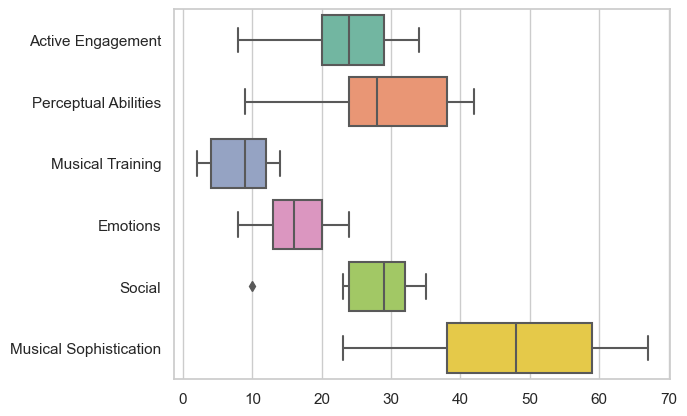

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# plot results of musical indexes
sns.set(style="whitegrid")
ax = sns.boxplot(data=df_musical_indexes, orient="h", palette="Set2")
plt.show()


/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype

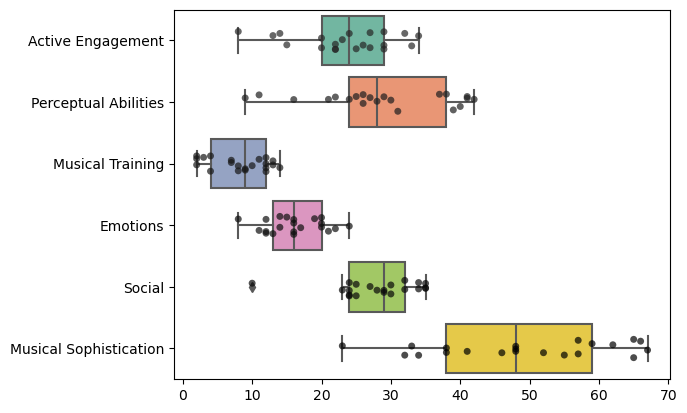

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.reset_orig()
ax = sns.boxplot(
    data=df_musical_indexes,
    orient="h",
    palette="Set2"
)

sns.stripplot(
    data=df_musical_indexes,
    orient="h",
    color="black",
    size=5,
    alpha=0.7,
    jitter=0.15,
    ax=ax
)
plt.show()

In [14]:
question_set8 = ['How much do you enjoy singing?',
                 'Were you formally trained to singing?',
                 'Did you recive any formal training on music theory?',
                 'The instrument I play best (including voice) is:',
                 'Do you have absolute pitch?']

asked_questions = df.keys()
norm_answers = np.zeros((len(df), len(asked_questions)))
for que_idx, question in enumerate(set):
    ques = question_sets[que_idx]
    norm = normaliz_sets[que_idx]
    ques_query, simi_query = find_similar_sentence_in_list(ques, 
                                                            asked_questions, 
                                                            equality=False, 
                                                            th_similarity=0.8, 
                                                            log=False)

    print('Question found!')
    print('- original: ', ques)
    print('- asked: ', ques_query)
    print('- similarity: ', simi_query)

    ans = df[ques_query]

    ans_norm = np.zeros(ans.shape)
    ans_norm[ans == 'No'] = 0
    ans_norm[ans == 'Yes'] = 1
    ans_norm[ans == 'Voice'] = 1
    ans_norm[ans == 'Voice/cello'] = 1
    ans_norm[ans == 'Baritone'] = 1

    norm_answers[:, set_idx] = ans_norm

print(norm_answers)

Question found!
- original:  ['I spend a lot of my free time doing music-related activities.', 'I enjoy writing about music, for example on blogs and forums.', "I'm intrigued by musical styles I'm not familiar with and want to find out more.", 'I often read or search the internet for things related to music.', "I don't spend much of my disposable income on music.", "Music is kind of an addiction for me - I couldn't live without it.", 'I keep track of new of music that I come across (e.g. new artists or recordings).', 'I have attended _ live music events as an audience member in the past twelve months.', 'I listen attentively to music for __ per day.']
- asked:  None
- similarity:  None


KeyError: None